<>:39: SyntaxWarning: invalid escape sequence '\g'
<>:43: SyntaxWarning: invalid escape sequence '\g'
<>:39: SyntaxWarning: invalid escape sequence '\g'
<>:43: SyntaxWarning: invalid escape sequence '\g'
C:\Users\julio\AppData\Local\Temp\ipykernel_1952\1142611264.py:39: SyntaxWarning: invalid escape sequence '\g'
  axes[2,0].imshow(s_gamma_05, cmap='gray'); axes[2,0].set_title('3. Gamma (\gamma = 0.5)')
C:\Users\julio\AppData\Local\Temp\ipykernel_1952\1142611264.py:43: SyntaxWarning: invalid escape sequence '\g'
  axes[3,0].imshow(s_gamma_20, cmap='gray'); axes[3,0].set_title('4. Gamma (\gamma = 2.0)')


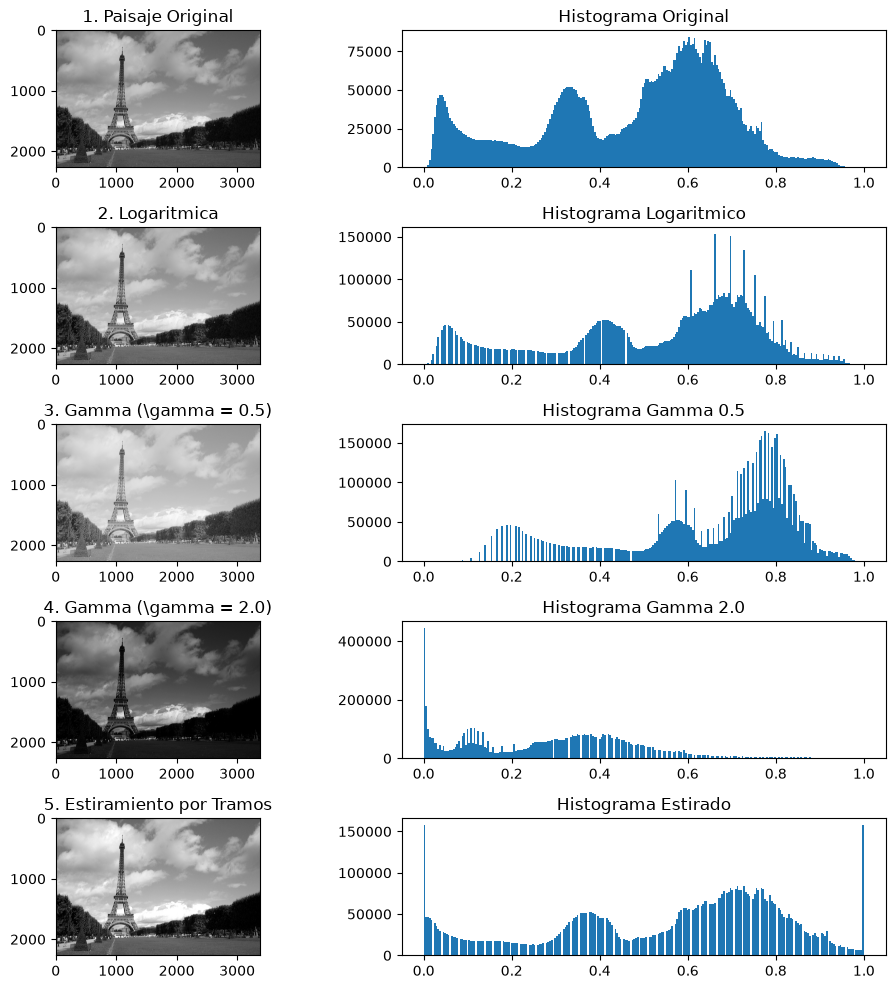

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

try:
    I_raw = plt.imread('paisaje.jpg')
except:
    I_raw = np.random.randint(0, 256, (255, 255), dtype=np.uint8)

if I_raw.ndim == 3:
    I_gray = np.dot(I_raw[...,:3], [0.2989, 0.5870, 0.1140])
else:
    I_gray = I_raw.copy()

r = I_gray / 255.0 

c = 1 / np.log(1 + np.max(r))
s_log = c * np.log(1 + r)

s_gamma_05 = r ** 0.5 
s_gamma_20 = r ** 2.0

p2, p98 = np.percentile(r, (2, 98))
s_stretch = np.clip((r - p2) / (p98 - p2), 0, 1)

fig, axes = plt.subplots(5, 2, figsize=(10, 10))
fig.canvas.manager.set_window_title('Transformaciones de Intensidad')

axes[0,0].imshow(r, cmap='gray'); axes[0,0].set_title('1. Paisaje Original')
axes[0,1].hist(r.ravel(), bins=256, range=[0, 1]); axes[0,1].set_title('Histograma Original')

axes[1,0].imshow(s_log, cmap='gray'); axes[1,0].set_title('2. Logaritmica')
axes[1,1].hist(s_log.ravel(), bins=256, range=[0, 1]); axes[1,1].set_title('Histograma Logaritmico')

axes[2,0].imshow(s_gamma_05, cmap='gray'); axes[2,0].set_title('3. Gamma (\gamma = 0.5)')
axes[2,1].hist(s_gamma_05.ravel(), bins=256, range=[0, 1]); axes[2,1].set_title('Histograma Gamma 0.5')

axes[3,0].imshow(s_gamma_20, cmap='gray'); axes[3,0].set_title('4. Gamma (\gamma = 2.0)')
axes[3,1].hist(s_gamma_20.ravel(), bins=256, range=[0, 1]); axes[3,1].set_title('Histograma Gamma 2.0')

axes[4,0].imshow(s_stretch, cmap='gray'); axes[4,0].set_title('5. Estiramiento por Tramos')
axes[4,1].hist(s_stretch.ravel(), bins=256, range=[0, 1]); axes[4,1].set_title('Histograma Estirado')

plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

def generate_concentrated_image(shape=(256, 256)):
    # Genera una imagen en escala de grises de 8 bits con concentracion en tonos oscuros/medios
    np.random.seed(42)
    # Distribucion concentrada alrededor de r = 65 con baja varianza
    base = np.random.normal(loc=65, scale=18, size=shape)
    img = np.clip(base, 0, 255).astype(np.uint8)
    return img

def histogram_specification(img, mu=128, sigma=40):
    # Realiza la ecualizacion y especificacion de histograma a una Gaussiana N(mu, sigma)
    MN = img.size
    
    # 1. Histograma normalizado (PDF) y CDF original
    hist_orig, _ = np.histogram(img.flatten(), bins=256, range=(0, 256))
    pdf_orig = hist_orig / MN
    cdf_orig = np.cumsum(pdf_orig)
    
    # 2. Ecualizacion estandar
    img_eq = np.round(cdf_orig[img] * 255.0).astype(np.uint8)
    
    # 3. PDF y CDF objetivo (Gaussiana truncada a [0, 255])
    r = np.arange(256)
    pdf_target = np.exp(-0.5 * ((r - mu) / sigma) ** 2)
    pdf_target /= pdf_target.sum()  # Normalizacion de la PDF objetivo
    cdf_target = np.cumsum(pdf_target)
    
    # 4. Especificacion: Mapeo z = G^-1[S(r)]
    mapping = np.zeros(256, dtype=np.uint8)
    for r_k in range(256):
        # Seleccionar z que minimice |CDF_target(z) - CDF_orig(r_k)|
        diff = np.abs(cdf_target - cdf_orig[r_k])
        mapping[r_k] = np.argmin(diff)
        
    img_spec = mapping[img]
    
    # 5. PDF y CDF obtenidas despues de la especificacion
    hist_spec, _ = np.histogram(img_spec.flatten(), bins=256, range=(0, 256))
    pdf_spec = hist_spec / MN
    cdf_spec = np.cumsum(pdf_spec)
    
    return img_eq, img_spec, pdf_orig, cdf_orig, pdf_target, cdf_target, pdf_spec, cdf_spec

def interactive_lab_5_2():
    img = generate_concentrated_image()
    
    @interact(
        mu=widgets.IntSlider(min=50, max=200, step=1, value=128, description='Media (μ):'),
        sigma=widgets.IntSlider(min=10, max=80, step=1, value=40, description='Desv. (σ):')
    )
    def update(mu, sigma):
        img_eq, img_spec, pdf_orig, cdf_orig, pdf_target, cdf_target, pdf_spec, cdf_spec = (
            histogram_specification(img, mu, sigma)
        )
        
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        
        # Visualizacion de Imagenes
        axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
        axes[0, 0].set_title("Original (Concentrada)")
        axes[0, 0].axis('off')
        
        axes[0, 1].imshow(img_eq, cmap='gray', vmin=0, vmax=255)
        axes[0, 1].set_title("Ecualizada (CDF Uniforme)")
        axes[0, 1].axis('off')
        
        axes[0, 2].imshow(img_spec, cmap='gray', vmin=0, vmax=255)
        axes[0, 2].set_title(f"Especificada (μ={mu}, σ={sigma})")
        axes[0, 2].axis('off')
        
        # Gráficas de PDF y CDF
        axes[1, 0].plot(pdf_orig, color='black', label='PDF Orig')
        axes[1, 0].plot(cdf_orig, color='blue', linestyle='--', label='CDF Orig')
        axes[1, 0].set_title("PDF y CDF Original")
        axes[1, 0].set_ylim([0, 1.05])
        axes[1, 0].legend(loc='center right')
        axes[1, 0].grid(True)
        
        axes[1, 1].plot(pdf_target, color='green', label='PDF Target')
        axes[1, 1].plot(cdf_target, color='darkgreen', linestyle='--', label='CDF Target')
        axes[1, 1].set_title("PDF y CDF Objetivo")
        axes[1, 1].set_ylim([0, 1.05])
        axes[1, 1].legend(loc='center right')
        axes[1, 1].grid(True)
        
        axes[1, 2].plot(pdf_spec, color='red', label='PDF Obt')
        axes[1, 2].plot(cdf_spec, color='darkred', linestyle='--', label='CDF Obt')
        axes[1, 2].set_title("PDF y CDF Obtenida")
        axes[1, 2].set_ylim([0, 1.05])
        axes[1, 2].legend(loc='center right')
        axes[1, 2].grid(True)
        
        plt.tight_layout()
        plt.show()

interactive_lab_5_2()

interactive(children=(IntSlider(value=128, description='Media (μ):', max=200, min=50), IntSlider(value=40, des…

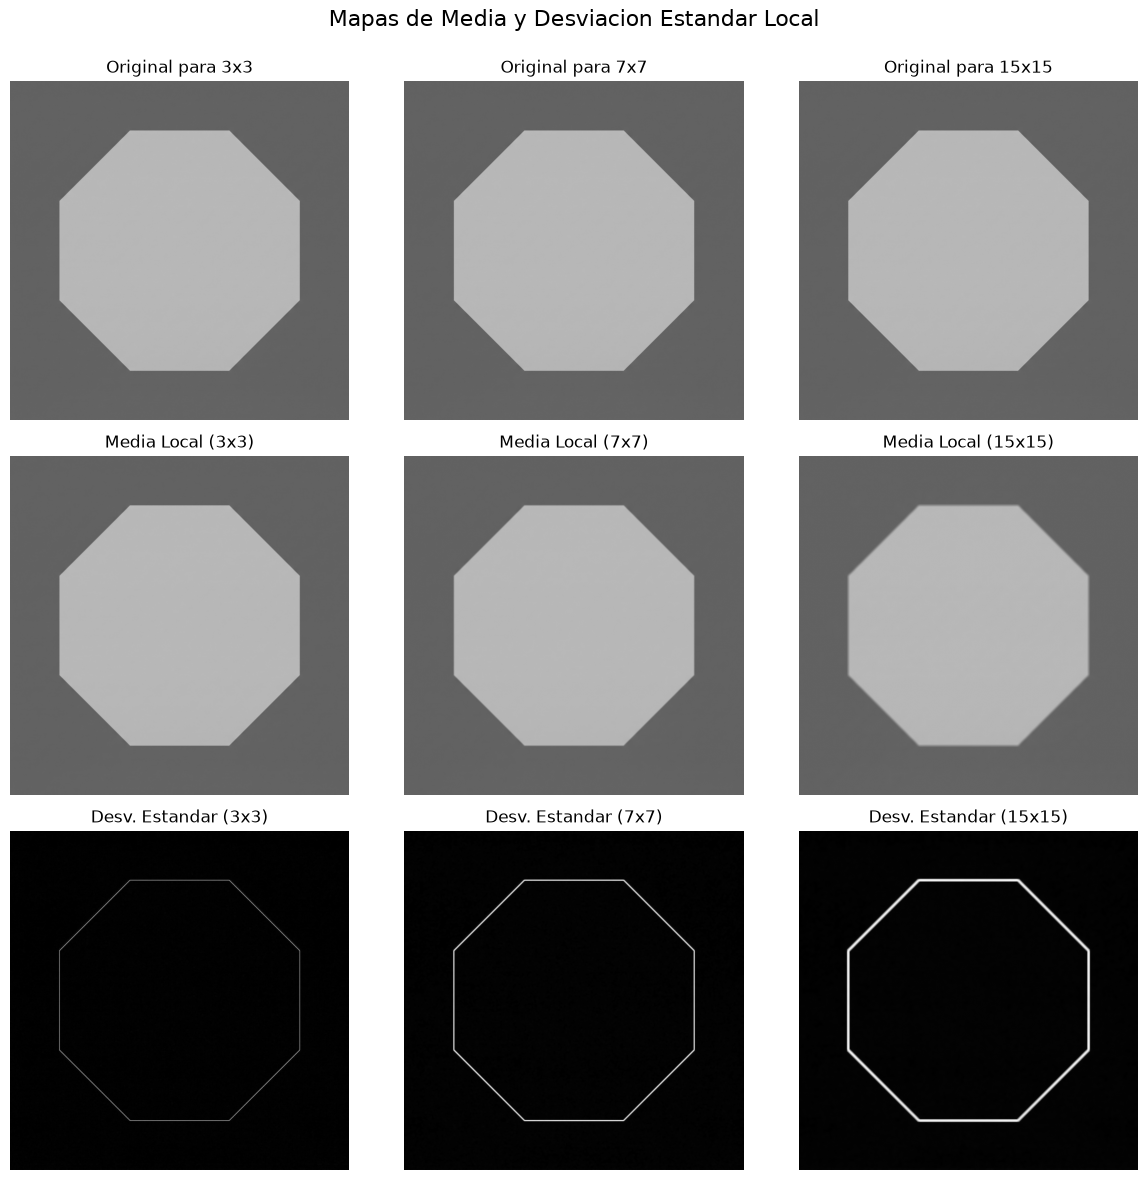

In [15]:
# MEDIA Y DESVIACION ESTANDAR LOCAL 
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
nombre_archivo = 'imagen_prueba.jpg'
try:
    I_raw = plt.imread(nombre_archivo)
    # Convertir a escala de grises si tiene 3 canales (RGB)
    if I_raw.ndim == 3:
        r = np.dot(I_raw[...,:3], [0.2989, 0.5870, 0.1140])
    else:
        r = I_raw.copy()
    # Normalizar al rango [0, 1]
    if r.max() > 1.0:
        r = r.astype(np.float32) / 255.0
except FileNotFoundError:
    print(f"Generando imagen de respaldo...")
    r = np.ones((400, 400), dtype=np.float32) * 0.3
    r[100:300, 100:300] = 0.8
    
# 2. Funcion para calcular estadisticas locales
def local_stats_numpy(img, win_size):
    pad_size = win_size // 2  
    # Rellenar los bordes (padding) para mantener el tamano original
    img_padded = np.pad(img, pad_size, mode='edge')   
    # Extraer sub-ventanas eficientemente
    windows = sliding_window_view(img_padded, window_shape=(win_size, win_size))    
    # Calcular media (E[X])
    mean_map = np.mean(windows, axis=(2, 3))    
    # Calcular varianza: Var(X) = E[X^2] - (E[X])^2
    mean_sqr = np.mean(windows**2, axis=(2, 3))
    var_map = np.maximum(mean_sqr - mean_map**2, 0) # Evitar negativos   
    # Desviacion estandar
    std_map = np.sqrt(var_map)    
    return mean_map, std_map

# 3. Calcular mapas y visualizar
w_sizes = [3, 7, 15]
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle('Mapas de Media y Desviacion Estandar Local', fontsize=16)

for i, w in enumerate(w_sizes):
    mu, sigma = local_stats_numpy(r, w)  
    axes[0, i].imshow(r, cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f'Original para {w}x{w}')
    axes[0, i].axis('off')  
    
    axes[1, i].imshow(mu, cmap='gray', vmin=0, vmax=1)
    axes[1, i].set_title(f'Media Local ({w}x{w})')
    axes[1, i].axis('off')   
    
    axes[2, i].imshow(sigma, cmap='gray')
    axes[2, i].set_title(f'Desv. Estandar ({w}x{w})')
    axes[2, i].axis('off')
    
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

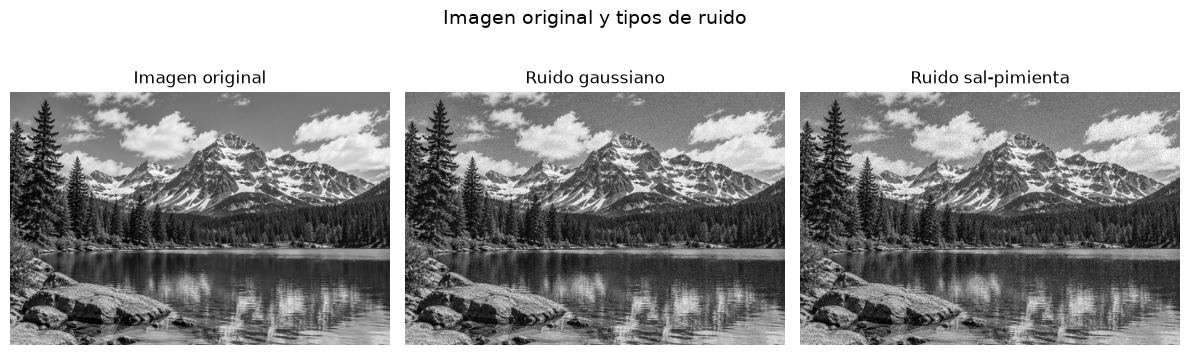

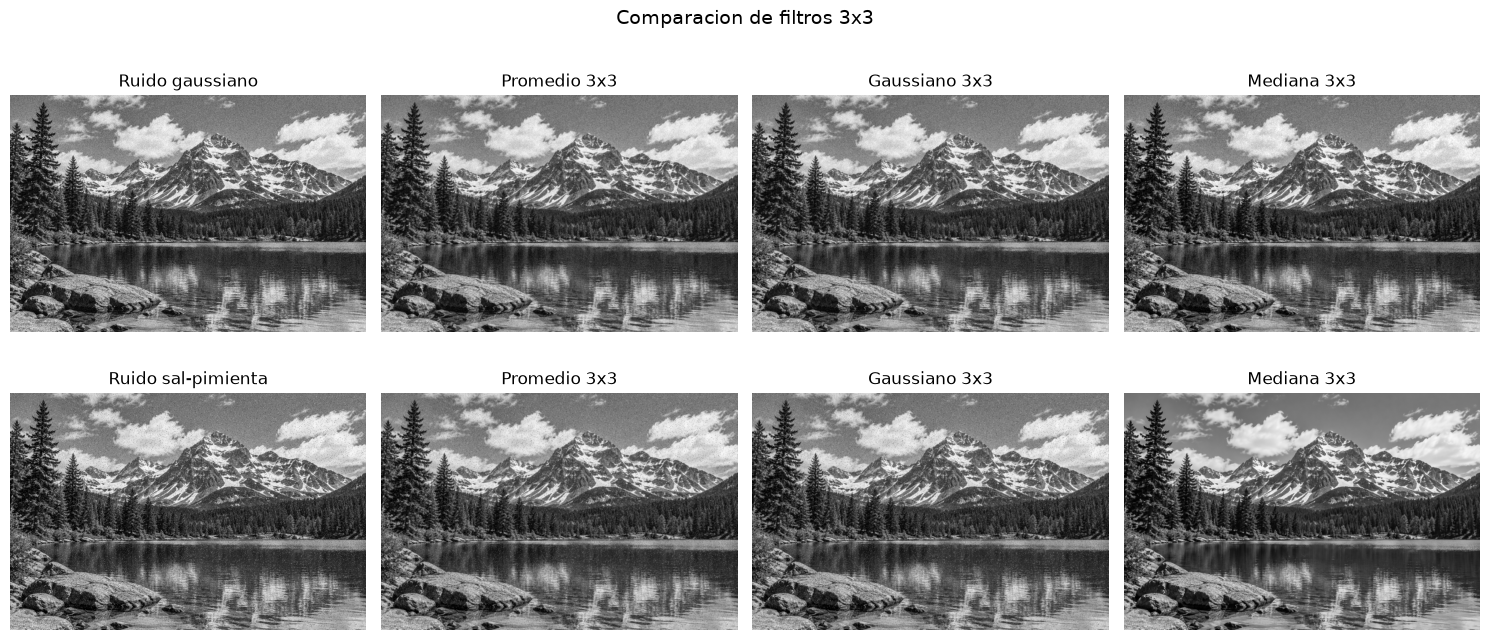

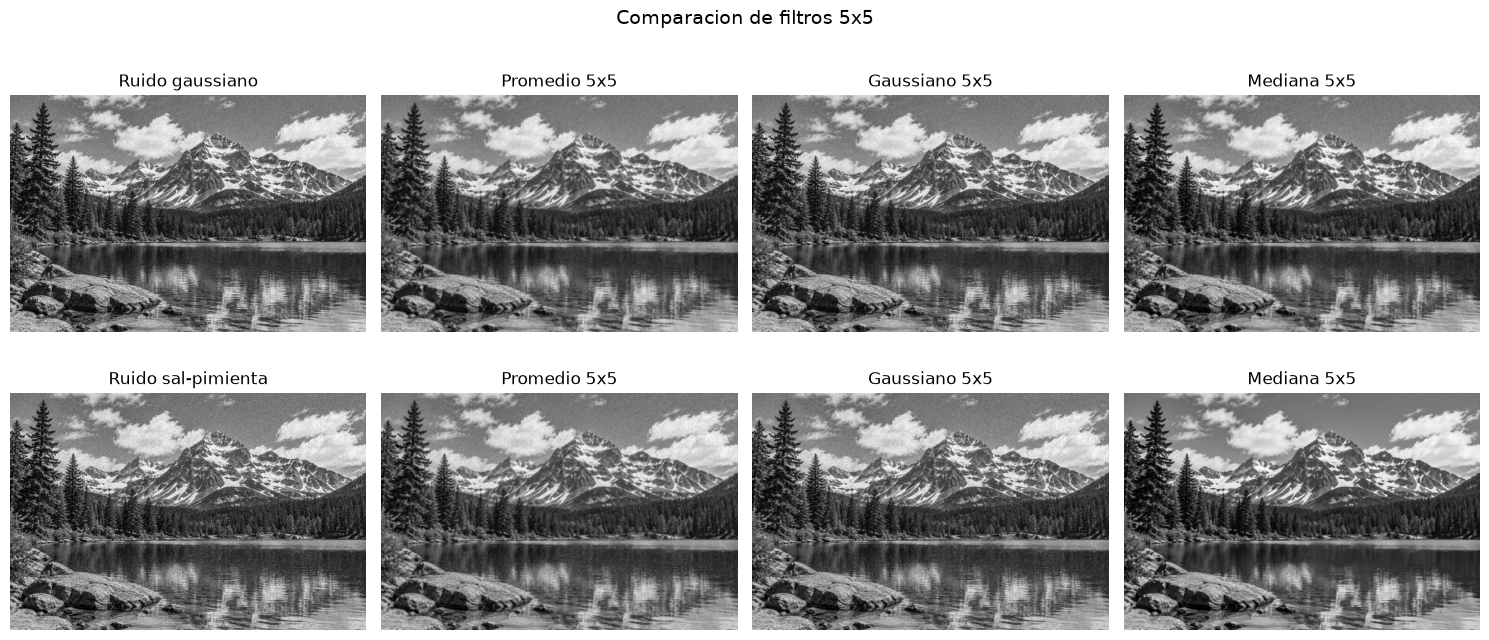

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter, gaussian_filter, median_filter

ruta = 'Lago alpino entre montañas nevadas.png'

I_raw = plt.imread(ruta)

if I_raw.ndim == 3:
    I_gray = np.dot(
        I_raw[..., :3],
        [0.2989, 0.5870, 0.1140]
    )
else:
    I_gray = I_raw.copy()

I_gray = I_gray.astype(np.float64)

if I_gray.max() > 1:
    I = I_gray / 255.0
else:
    I = I_gray.copy()

I = np.clip(I, 0, 1)

np.random.seed(42)

ruido_g = np.random.normal(
    loc=0,
    scale=0.1,
    size=I.shape
)

I_gauss = np.clip(I + ruido_g, 0, 1)

I_sp = I.copy()

probs = np.random.rand(*I.shape)

I_sp[probs < 0.025] = 0.0
I_sp[(probs >= 0.025) & (probs < 0.05)] = 1.0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

fig.suptitle('Imagen original y tipos de ruido', fontsize=14)

imagenes = [I, I_gauss, I_sp]

titulos = [
    'Imagen original',
    'Ruido gaussiano',
    'Ruido sal-pimienta'
]

for ax, img, titulo in zip(axes, imagenes, titulos):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.axis('off')

plt.tight_layout()
plt.savefig('tipos_ruido.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

tamanos = [3, 5]

for n in tamanos:

    P_g = uniform_filter(
        I_gauss,
        size=n,
        mode='reflect'
    )

    G_g = gaussian_filter(
        I_gauss,
        sigma=0.8,
        radius=n//2,
        mode='reflect'
    )

    M_g = median_filter(
        I_gauss,
        size=n,
        mode='reflect'
    )

    P_sp = uniform_filter(
        I_sp,
        size=n,
        mode='reflect'
    )

    G_sp = gaussian_filter(
        I_sp,
        sigma=0.8,
        radius=n//2,
        mode='reflect'
    )

    M_sp = median_filter(
        I_sp,
        size=n,
        mode='reflect'
    )

    fig, axes = plt.subplots(2, 4, figsize=(15, 7))

    fig.suptitle(
        f'Comparacion de filtros {n}x{n}',
        fontsize=14
    )

    imagenes = [
        I_gauss, P_g, G_g, M_g,
        I_sp, P_sp, G_sp, M_sp
    ]

    titulos = [
        'Ruido gaussiano',
        f'Promedio {n}x{n}',
        f'Gaussiano {n}x{n}',
        f'Mediana {n}x{n}',
        'Ruido sal-pimienta',
        f'Promedio {n}x{n}',
        f'Gaussiano {n}x{n}',
        f'Mediana {n}x{n}'
    ]

    for ax, img, titulo in zip(
        axes.flatten(),
        imagenes,
        titulos
    ):
        ax.imshow(
            img,
            cmap='gray',
            vmin=0,
            vmax=1
        )
        ax.set_title(titulo)
        ax.axis('off')

    plt.tight_layout()

    plt.savefig(
        f'filtros_{n}x{n}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

Generando imagen sintética con textura...
Imagen base guardada como 'textura_generada.jpg'


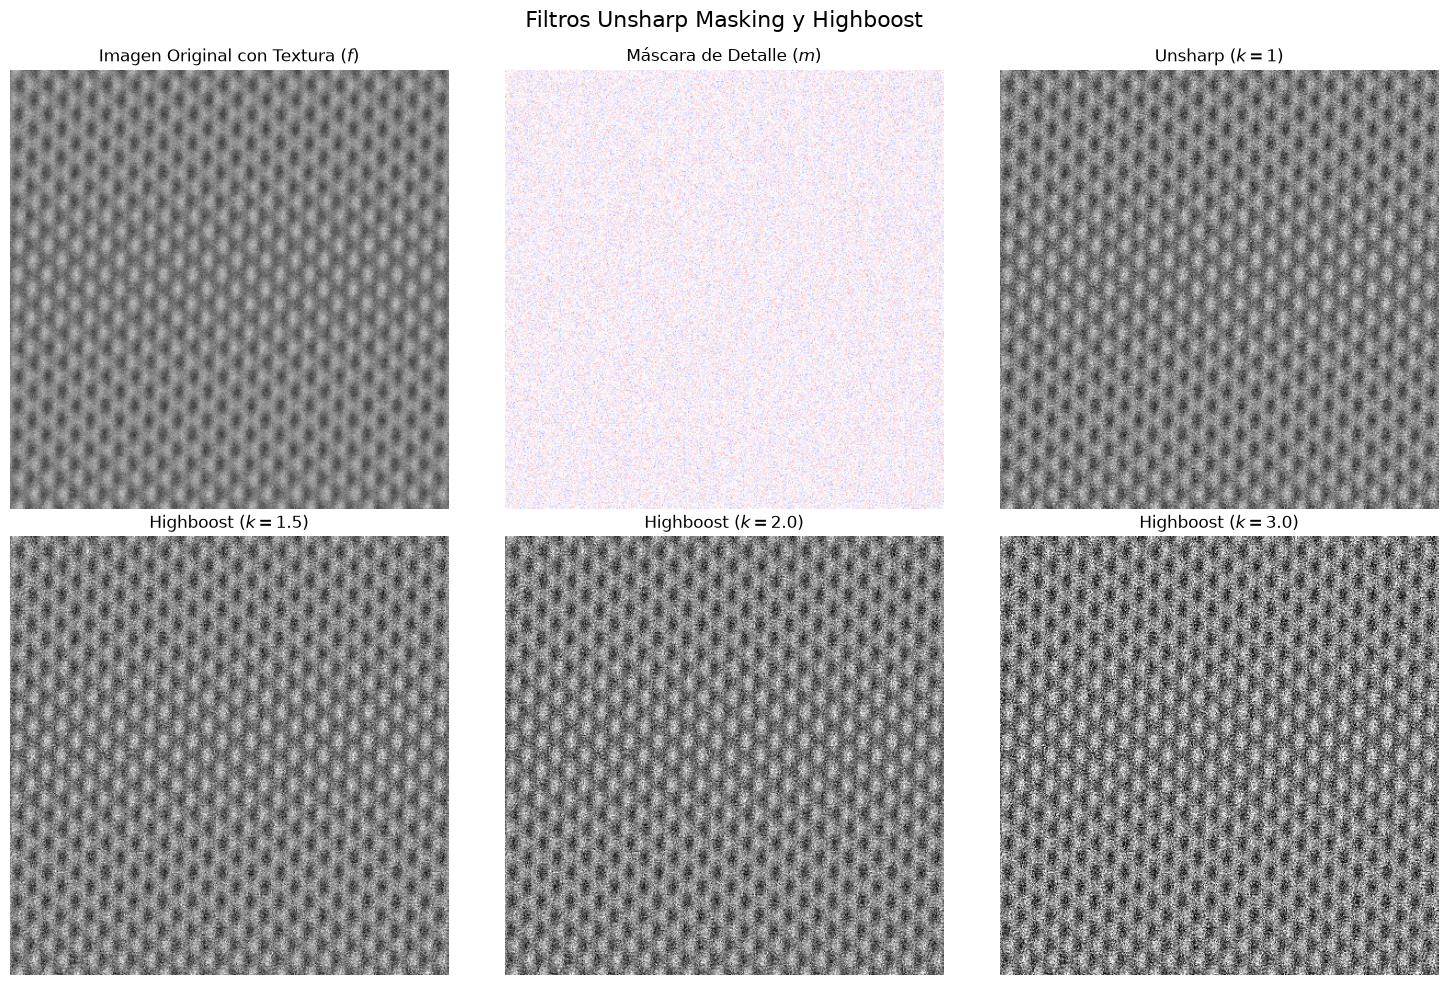

In [14]:
# 5.7 UNSHARP Y HIGHBOOST 
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
print("Generando imagen sintética con textura...")
# Crear una malla de coordenadas
x = np.linspace(0, 10, 400)
y = np.linspace(0, 10, 400)
X, Y = np.meshgrid(x, y)
# Crear una textura basada en ondas sinusoidales superpuestas de alta frecuencia
textura = np.sin(2 * np.pi * X * 1.5) * np.cos(2 * np.pi * Y * 1.5)
textura += 0.5 * np.sin(2 * np.pi * X * 3.0 + Y)
# Normalizar la textura al rango [0.3, 0.7] para dejar espacio a los realces
textura = (textura - textura.min()) / (textura.max() - textura.min())
textura = textura * 0.4 + 0.3
# Añadir algo de ruido gaussiano para simular una textura real o imperfecciones del sensor
np.random.seed(42)
ruido = 0.05 * np.random.randn(400, 400)
f = np.clip(textura + ruido, 0, 1).astype(np.float32)
# Guardar la imagen generada para que la puedas incluir en tu informe
plt.imsave('textura_generada.jpg', f, cmap='gray')
print("Imagen base guardada como 'textura_generada.jpg'")
def blur_numpy(img, win_size=5):
    """Aplica un filtro de promediado local (suavizado)."""
    pad_size = win_size // 2
    # Rellenar los bordes para mantener las dimensiones
    img_padded = np.pad(img, pad_size, mode='edge')
    # Extraer las ventanas y calcular la media
    windows = sliding_window_view(img_padded, window_shape=(win_size, win_size))
    return np.mean(windows, axis=(2, 3))

# Obtener imagen suavizada (f_bar) con ventana 5x5
f_bar = blur_numpy(f, win_size=5)
# Obtener la máscara de detalle (m = f - f_bar)
m = f - f_bar
# Aplicar realces: g = f + k * m
g_unsharp = np.clip(f + 1.0 * m, 0, 1)  # Unsharp Masking (k = 1)
g_hb_1_5  = np.clip(f + 1.5 * m, 0, 1)  # Highboost con k = 1.5
g_hb_2_0  = np.clip(f + 2.0 * m, 0, 1)  # Highboost con k = 2.0
g_hb_3_0  = np.clip(f + 3.0 * m, 0, 1)  # Highboost con k = 3.0
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Filtros Unsharp Masking y Highboost', fontsize=16)

titulos = [
    'Imagen Original con Textura ($f$)', 
    'Máscara de Detalle ($m$)', 
    'Unsharp ($k=1$)', 
    'Highboost ($k=1.5$)', 
    'Highboost ($k=2.0$)', 
    'Highboost ($k=3.0$)'     ]
imagenes = [f, m, g_unsharp, g_hb_1_5, g_hb_2_0, g_hb_3_0]
for i, ax in enumerate(axes.flat):
    if i == 1:
        # La máscara de detalle tiene valores negativos y positivos, 
        ax.imshow(imagenes[i], cmap='bwr', vmin=-0.5, vmax=0.5)
    else:
        # El resto de las imágenes se grafican en escala de grises [0, 1]
        ax.imshow(imagenes[i], cmap='gray', vmin=0, vmax=1)
    ax.set_title(titulos[i])
    ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()